# Advanced Apex Project I
## Forecasting Hourly Metro Interstate Traffic Volume
**Specialization / Project:** N4 regression-based time-series forecasting methodology

**Name:** D H Sai Nagendra

**Id:** 2025EM1300051

**M.Sc. Data Science & AI, BITS Pilani Digital**  

**Report date:** 31 October 2026

**Forecast horizon:** one hour ahead, target hourly westbound vehicle volume (vehicles/hour)


**Research question:** How accurately can next-hour westbound I-94 volume be predicted from actual historical counts and calendar information? Which additional changes and forecast horizons expose strengths and weaknesses?



In [39]:
import numpy as np
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':160, 'font.size':10})
RANDOM_STATE = 42
SOURCE_NAME= 'Raw_Dataset_Metro_Traffic.xlsx'
DATA=Path(SOURCE_NAME)
if not DATA.exists():
  raise FileNotFoundError(f'File Raw_Dataset_Metro_Traffic.xlsx is not found')
OUT=Path('N4_APEX_FINAL_OUTPUTS')
OUT.mkdir(parents=True, exist_ok=True)
REQUIRED=['holiday','temp','rain_1h','snow_1h','clouds_all','weather_main','weather_description','date_time','traffic_volume']
raw=pd.read_excel(DATA, keep_default_na=False)
print('Source:',DATA.name, '| Source shape:',raw.shape)
display(raw.head(5))


Source: Raw_Dataset_Metro_Traffic.xlsx | Source shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 1. Source understanding and data dictionary
The dataset is the **UCI Metro Interstate Traffic Volume** data, describing a westbound I-94 road segment with hourly counts (2012–2018). The traffic target is a **count of vehicles in an hour**, not a website session/click count. Numeric weather fields are measured **at the hour** and should not automatically be treated as known one hour earlier.

| Column | Meaning / unit | Checkpoint decision |
|---|---|---|
| `date_time` | Source hourly timestamp | Convert to datetime; enforce hourly grid |
| `traffic_volume` | Vehicle count per hour | Forecast target; don't impute missing hours |
| `holiday` | Public-holiday label (`None` = **not a holiday**) | Keep as descriptive category; no implicit NA |
| `temp` | Temperature in Kelvin | Audit impossible 0 K readings; descriptive only |
| `rain_1h`, `snow_1h` | Precipitation in millimetres | Audit extreme values / zero inflation; descriptive only |
| `clouds_all` | Cloud cover (%) | Check numeric range; descriptive only |
| `weather_main`, `weather_description` | Weather labels | Normalize description for descriptive analysis |

**Data Source:** UCI Machine Learning Repository, dataset 492: https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume

In [40]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              48204 non-null  object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


## 1.1 Parsing the data

In [41]:
original_types=raw.dtypes.astype(str).rename('stored_dtype').to_frame()
num_fields=['temp','rain_1h','snow_1h','clouds_all','traffic_volume']
for col in num_fields:
    raw[col]=pd.to_numeric(raw[col],errors='coerce')
raw['date_time']=pd.to_datetime(raw['date_time'], errors='coerce')
raw['holiday']=raw['holiday'].astype(str).str.strip().replace({'':'None'})
raw['weather_main']=raw['weather_main'].astype(str).str.strip()
raw['weather_description']=raw['weather_description'].astype(str).str.strip()
raw['weather_description_norm']=raw['weather_description'].str.casefold()
parsed_types=raw[REQUIRED].dtypes.astype(str).rename('parsed_dtype').to_frame()
print('Datatype audit:')
display(original_types.join(parsed_types))
print('Failed numeric conversions:', raw[num_fields].isna().sum().to_dict())
print('Invalid timestamps:',int(raw.date_time.isna().sum()))

Datatype audit:


,stored_dtype,parsed_dtype
holiday,object,object
temp,float64,float64
rain_1h,float64,float64
snow_1h,float64,float64
clouds_all,int64,int64
weather_main,object,object
weather_description,object,object
date_time,object,datetime64[ns]
traffic_volume,int64,int64


Failed numeric conversions: {'temp': 0, 'rain_1h': 0, 'snow_1h': 0, 'clouds_all': 0, 'traffic_volume': 0}
Invalid timestamps: 0


## 2. Data-quality evidence — addressed Outline feedback

**Crucial distinction:** An **exact duplicate** is a completely identical original nine-field row. A **repeated hourly timestamp** may instead represent multiple weather observations describing the *same* target-hour vehicle count. They must not be interpreted as multiple independent targets. A duplicated-date *calendar day* is a different concept again.

For weather, this checkpoint uses explicit, *exploratory* quality screens: impossible `temp <= 0 K`; negative precipitation; `rain_1h > 100 mm` is flagged for plausibility review (not automatically proof of an error). Target volumes on these rows remain intact. Contemporaneous observed weather is excluded from the one-hour-ahead regression.

In [42]:
exact=int(raw.duplicated().sum())
extra_timestamp=int(raw.date_time.duplicated().sum())
unique_hours=int(raw.date_time.nunique())
volume_disagreement=(raw.groupby('date_time').traffic_volume.nunique(dropna=False)>1)
conflict_hours=int(volume_disagreement.sum())
quality_checks={
    'Source rows':len(raw),'Exact duplicate original rows':exact,
    'Repeated timestamp extra rows':extra_timestamp,
    'Distinct observed hourly timestamps':unique_hours,
    'Hours with disagreeing traffic target':conflict_hours,
    'Zero Kelvin temperatures':int((raw.temp==0).sum()),
    'Temperature min K':float(raw.temp.min()),
    'Rainfall max mm per hour':float(raw.rain_1h.max()),
    'Rainfall > 100 mm per hour':int((raw.rain_1h>100).sum()),
    'Zero rainfall rows':int((raw.rain_1h==0).sum()),
    'Zero snowfall rows':int((raw.snow_1h==0).sum()),
    'Holiday = None rows':int(raw.holiday.eq('None').sum()),
    'Clouds outside 0 to 100':int((~raw.clouds_all.between(0,100)).sum()),
    'Missing source cells after parsing':int(raw.isna().sum().sum()),
}
quality_table=pd.DataFrame(list(quality_checks.items()),columns=['Quality measure','Observed value'])
display(quality_table)

,Quality measure,Observed value
0,Source rows,48204.0
1,Exact duplicate original rows,17.0
2,Repeated timestamp extra rows,7629.0
3,Distinct observed hourly timestamps,40575.0
4,Hours with disagreeing traffic target,0.0
5,Zero Kelvin temperatures,10.0
6,Temperature min K,0.0
7,Rainfall max mm per hour,9831.3
8,Rainfall > 100 mm per hour,1.0
9,Zero rainfall rows,44737.0


In [43]:
display(raw['holiday'].unique())
display(raw['weather_main'].unique())

array(['None', 'Columbus Day', 'Veterans Day', 'Thanksgiving Day',
       'Christmas Day', 'New Years Day', 'Washingtons Birthday',
       'Memorial Day', 'Independence Day', 'State Fair', 'Labor Day',
       'Martin Luther King Jr Day'], dtype=object)

array(['Clouds', 'Clear', 'Rain', 'Drizzle', 'Mist', 'Haze', 'Fog',
       'Thunderstorm', 'Snow', 'Squall', 'Smoke'], dtype=object)

In [44]:
variants=raw.loc[raw.weather_description_norm.eq('sky is clear'),'weather_description'].value_counts()
print(variants)



weather_description
sky is clear    11665
Sky is Clear     1726
Name: count, dtype: int64


In [45]:
print('Extreme rain records:')
display(raw.nlargest(5,'rain_1h')[['date_time','rain_1h','weather_main','traffic_volume']])
print('Zero Kelvin sample:')
display(raw.loc[raw.temp.eq(0),['date_time','temp','weather_main','traffic_volume']].head(12))

Extreme rain records:


,date_time,rain_1h,weather_main,traffic_volume
24872,2016-07-11 17:00:00,9831.30,Rain,5535
8247,2013-08-07 02:00:00,55.63,Rain,315
7179,2013-06-24 11:00:00,44.45,Rain,4802
25779,2016-08-16 17:00:00,31.75,Rain,4913
10806,2013-12-19 23:00:00,28.70,Rain,1190


Zero Kelvin sample:


,date_time,temp,weather_main,traffic_volume
11898,2014-01-31 03:00:00,0.0,Clear,361
11899,2014-01-31 04:00:00,0.0,Clear,734
11900,2014-01-31 05:00:00,0.0,Clear,2557
11901,2014-01-31 06:00:00,0.0,Clear,5150
11946,2014-02-02 03:00:00,0.0,Clear,291
11947,2014-02-02 04:00:00,0.0,Clear,284
11948,2014-02-02 05:00:00,0.0,Clear,434
11949,2014-02-02 06:00:00,0.0,Clear,739
11950,2014-02-02 07:00:00,0.0,Clear,962
11951,2014-02-02 08:00:00,0.0,Clear,1670


## 3. Cleaning, reconciling weather records and reconstructing hourly coverage

**Dataset-specific extension (faculty feedback):** For each timestamp, retain **one** target observation after verifying that all copies have identical traffic volume. Use the median target (equal to that common volume), mean of *plausible* numeric weather, and lexicographically deterministic modal weather labels. Store `source_records_at_hour` for traceability. This prevents double-weighting an hour in EDA or regression.

The selected >100 mm/h rainfall and 0 K screens change **descriptive weather values only**: they do **not** delete traffic observations, fill future weather, or alter the forecasting target. For weather descriptions, `str.strip().str.casefold()` merges capitalization variants. The original `.xlsx` remains unchanged.

In [46]:
# STEP 1: Remove exact duplicate rows

df = raw.drop_duplicates().copy()


# STEP 2: Handle invalid weather values

df.loc[df["temp"] <= 0, "temp"] = np.nan

df.loc[
    (df["rain_1h"] < 0) | (df["rain_1h"] > 100),
    "rain_1h"
] = np.nan

df.loc[df["snow_1h"] < 0, "snow_1h"] = np.nan

df.loc[
    (df["clouds_all"] < 0) | (df["clouds_all"] > 100),
    "clouds_all"
] = np.nan


# STEP 3: Combine records belonging to the same hour

hourly = df.groupby("date_time").agg({
    "traffic_volume": "median",
    "temp": "mean",
    "rain_1h": "mean",
    "snow_1h": "mean",
    "clouds_all": "mean"
})


# STEP 4: Select the most common weather category

weather = df.groupby("date_time")["weather_main"].agg(
    lambda x: sorted(x.mode())[0]
)

hourly["weather_main"] = weather


# STEP 5: Add holiday information

holiday = df.groupby("date_time")["holiday"].agg(
    lambda x: sorted(x.mode())[0]
)

hourly["holiday"] = holiday


# STEP 6: Create a complete hourly timeline

start = hourly.index.min()
end = hourly.index.max()

all_hours = pd.date_range(start=start, end=end, freq="h")

hourly = hourly.reindex(all_hours)

hourly.index.name = "date_time"


# STEP 7: Count missing hours

missing_hours = hourly["traffic_volume"].isna().sum()

total_hours = len(hourly)

observed_hours = hourly["traffic_volume"].notna().sum()

missing_percentage = (missing_hours / total_hours) * 100


# STEP 8: Count completely missing days

daily_count = hourly["traffic_volume"].resample("D").count()

missing_days = (daily_count == 0).sum()


# STEP 9: Display results

print("Total calendar hours:", total_hours)
print("Observed hours:", observed_hours)
print("Missing hours:", missing_hours)
print("Missing percentage:", round(missing_percentage, 2))
print("Completely missing days:", missing_days)

display(hourly.head())

Total calendar hours: 52551
Observed hours: 40575
Missing hours: 11976
Missing percentage: 22.79
Completely missing days: 330


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,holiday
date_time,,,,,,,
2012-10-02 09:00:00,5545.0,288.28,0.0,0.0,40.0,Clouds,None
2012-10-02 10:00:00,4516.0,289.36,0.0,0.0,75.0,Clouds,None
2012-10-02 11:00:00,4767.0,289.58,0.0,0.0,90.0,Clouds,None
2012-10-02 12:00:00,5026.0,290.13,0.0,0.0,90.0,Clouds,None
2012-10-02 13:00:00,4918.0,291.14,0.0,0.0,75.0,Clouds,None


### Decisions

Duplicate timestamp records are consolidated to one hourly target (median; equivalent to the common value when duplicates agree), mean numeric weather and modal categorical weather. A complete hourly calendar is constructed; missing target hours remain NaN. For modeling, target rows and lag/rolling feature rows with insufficient observed history are excluded rather than inventing target observations. This produces 16,909 eligible supervised observations.

### Interpretation of data quality
- A large missing-hour fraction is a **sampling/coverage limitation**, not evidence of zero demand.
- Reporting missing calendar *days* is not a substitute for reporting missing *hours*.
- After date consolidation, each observed hour has the original target count, but weather summaries may combine several textual descriptions.
- Rare rain, snow and holiday conditions are too sparse for strong subgroup or causal claims.
- Conditions flagged as physically implausible are withheld from **weather summaries** and do not remove otherwise legitimate target measurements.

# 4. Exploratory data analysis

We inspect the actual distribution, trend/gaps, seasonality and calendar patterns. Plots use **observed hours only** for means, and **gaps remain visible** in the chronological series. These are descriptive comparisons and do not identify causes (for example, weather groups are confounded by the time of day and season).


### 4.1 Temporal Coverage Analysis

Before building a forecasting model, it is important to examine the completeness of the dataset.

The objectives of this analysis are:
1. Calculate the percentage of available hourly traffic observations for each year.
2. Examine monthly variations in data availability.
3. Identify periods with substantial missing observations.
4. Understand how missing timestamps may affect time-series forecasting.

#### 4.1.2 What are we trying to plot?

a) Yearly Traffic Data Coverage- What percentage of the expected hourly traffic measurements is available in each year?

b) Monthly Traffic Data Coverage- Are missing traffic observations concentrated in particular months?


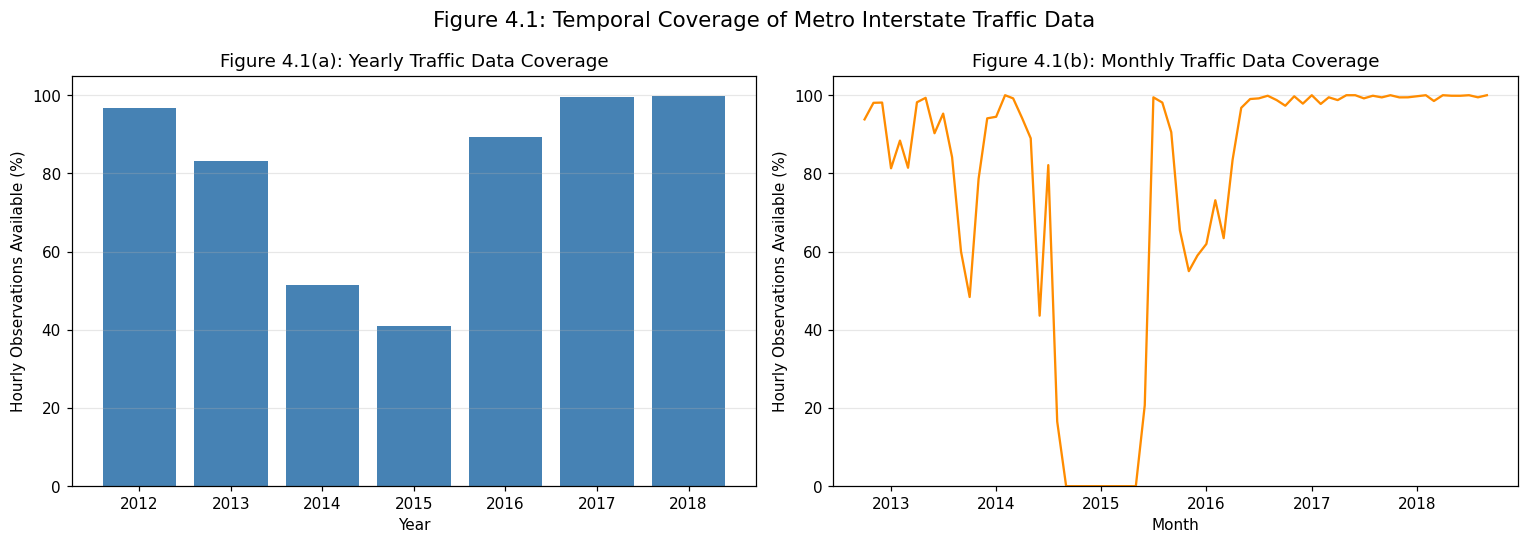

Table 4.1: Yearly Traffic Data Coverage


,observed_hours,expected_hours,coverage_pct
date_time,,,
2012,2103,2175,96.689655
2013,7294,8760,83.264840
2014,4501,8760,51.381279
2015,3593,8760,41.015982
2016,7838,8784,89.230419
2017,8713,8760,99.463470
2018,6533,6552,99.710012


In [47]:
# STEP 1: Identify available traffic observations

available = hourly["traffic_volume"].notna()


# STEP 2: Calculate yearly coverage

coverage_by_year = available.groupby(hourly.index.year).agg(
    ["sum", "count", "mean"]
)

coverage_by_year.columns = [
    "observed_hours",
    "expected_hours",
    "coverage_fraction"
]

coverage_by_year["coverage_pct"] = (
    coverage_by_year["coverage_fraction"] * 100
)


# STEP 3: Calculate monthly coverage

monthly_cov = available.resample("MS").mean() * 100


# STEP 4: Create the figure

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# STEP 5: Figure 3.1(a) - Yearly coverage

axes[0].bar(
    coverage_by_year.index,
    coverage_by_year["coverage_pct"],
    color="steelblue"
)

axes[0].set_title("Figure 4.1(a): Yearly Traffic Data Coverage")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Hourly Observations Available (%)")
axes[0].set_ylim(0, 105)
axes[0].grid(axis="y", alpha=0.3)


# STEP 6: Figure 3.1(b) - Monthly coverage

axes[1].plot(
    monthly_cov.index,
    monthly_cov.values,
    color="darkorange"
)

axes[1].set_title("Figure 4.1(b): Monthly Traffic Data Coverage")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Hourly Observations Available (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(axis="y", alpha=0.3)


# STEP 7: Add an overall figure title

fig.suptitle(
    "Figure 4.1: Temporal Coverage of Metro Interstate Traffic Data",
    fontsize=14
)

plt.tight_layout()


# STEP 8: Save and display the figure

plt.savefig(
    OUT / "01_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# STEP 9: Display yearly coverage statistics

print("Table 4.1: Yearly Traffic Data Coverage")

display(
    coverage_by_year[
        ["observed_hours", "expected_hours", "coverage_pct"]
    ]
)

#### 4.1.3 Observations

**Figure 4.1(a): Yearly Traffic Data Coverage**

1. The dataset covers the period from 2012 to 2018, with considerable variation in hourly data availability across different years.

2. The highest coverage is observed during 2017 and 2018, when nearly 100% of the expected hourly traffic observations are available.

3. Data coverage decreases from approximately 97% in 2012 to 83% in 2013, followed by a substantial reduction to approximately 51% in 2014 and 41% in 2015.

4. Coverage improves significantly in 2016, reaching approximately 89%, and remains consistently high during 2017–2018.

**Figure 4.1(b): Monthly Traffic Data Coverage**

5. Monthly coverage fluctuates considerably between 2013 and 2016, indicating that missing observations are not uniformly distributed throughout the study period.

6. A prolonged period of approximately 0% coverage is visible from late 2014 through much of 2015. This indicates an extended interruption in the available traffic records.

7. Coverage begins recovering toward the end of 2015 but remains variable during the early part of 2016.

8. From approximately mid-2016 onward, monthly coverage remains consistently close to 100%, indicating substantially better continuity of hourly traffic observations.



#### 4.1.4 Inferences

**1. Missing observations are concentrated in specific periods.**

The large differences in yearly coverage and the extended low-coverage interval in Figure 4.1(b) suggest that missing observations occur in concentrated periods rather than being distributed evenly across the dataset.

**2. Historical data continuity varies significantly.**

The relatively poor coverage during 2014–2015 may reduce the number of usable training observations for forecasting models that depend on previous hourly traffic measurements.

**3. Missing periods affect lag-based feature engineering.**

The proposed forecasting model uses historical traffic features such as `lag_1`, `lag_24`, and `lag_168`. Extended gaps can prevent these features from being calculated, reducing the number of valid training samples.

**4. Later years provide more continuous observations.**

The consistently high coverage during 2017–2018 suggests that these periods provide more complete historical sequences for model evaluation. However, high data coverage alone does not guarantee better forecasting accuracy.

**5. Missing traffic observations should not be interpreted as zero traffic.**

The periods showing 0% coverage indicate the absence of recorded traffic measurements, not the absence of vehicles. Therefore, missing traffic observations should not automatically be replaced with zero.

#### 4.1.5 Conclusion

Figure 4.1 demonstrates that the Metro Interstate Traffic Volume dataset contains substantial variations in temporal coverage, particularly during 2014–2015. Data availability improves considerably from 2016 onward, with nearly complete hourly coverage during 2017–2018.

These findings highlight the importance of preserving the hourly timeline, identifying missing observations, and carefully constructing historical lag features before model training.

Consequently, the forecasting methodology should account for missing historical values and use chronological training and evaluation procedures to maintain the integrity of the time-series analysis.

### 4.2 Traffic Volume Patterns

The objective of this analysis is to understand the temporal characteristics and distribution of traffic volume in the Metro Interstate Traffic dataset.

Specifically, this analysis aims to:
1. Examine changes in average daily traffic volume over the study period.
2. Understand the distribution of hourly traffic observations.
3. Identify peak and low-traffic hours during a typical day.
4. Compare average traffic volume across different days of the week.
5. Identify recurring patterns that may be useful for traffic forecasting.

#### 4.2.1 What are we trying to plot?

a) Daily Mean Traffic Volume - Examine long-term traffic variation

b) Distribution of Hourly Traffic Volume - Understand the distribution of traffic observations

c) Average Traffic by Hour of Day - Identify daily peak and low-traffic hours

d) Average Traffic by Day of Week - Compare weekday and weekend traffic

Peak traffic hour: 16
Lowest traffic hour: 3
Average traffic during peak hour: 5708.61
Average traffic during lowest hour: 373.21


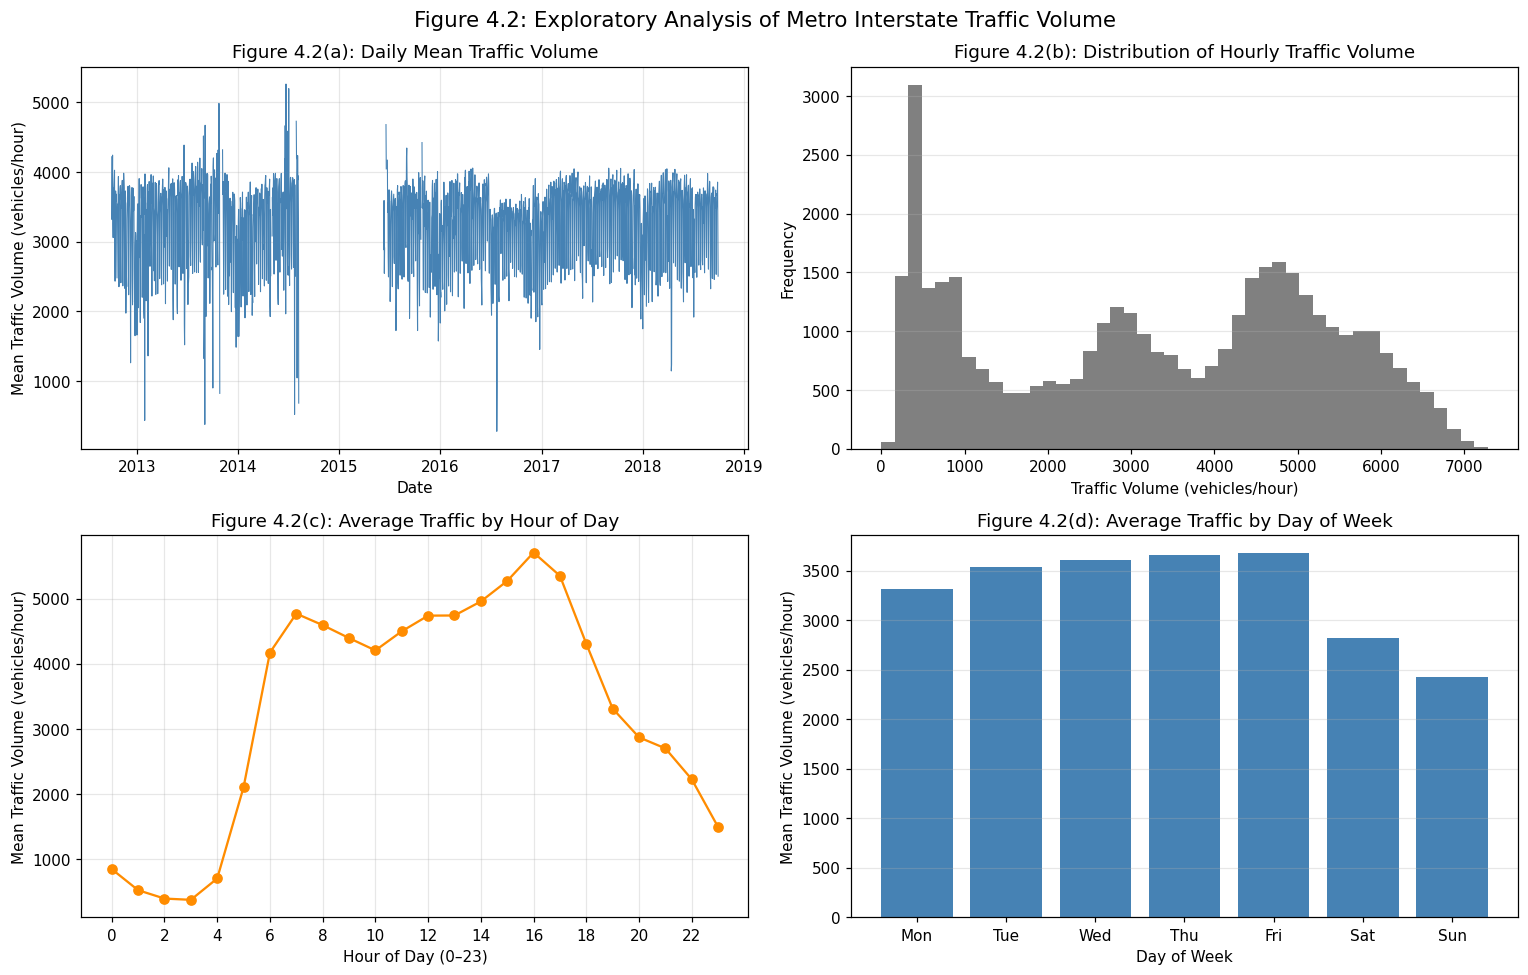

In [48]:
# STEP 1: Select rows with available traffic volume

observed = hourly.dropna(subset=["traffic_volume"]).copy()

# STEP 2: Calculate average traffic for each hour of the day

hour_stats = observed.groupby(observed.index.hour)["traffic_volume"].agg(
    ["mean", "median", "count"]
)


# STEP 3: Calculate average traffic for each day of the week

weekday_stats = observed.groupby(observed.index.dayofweek)["traffic_volume"].agg(
    ["mean", "median", "count"]
)


# STEP 4: Identify peak and lowest traffic hours

peak_hour = hour_stats["mean"].idxmax()

low_hour = hour_stats["mean"].idxmin()

print("Peak traffic hour:", peak_hour)
print("Lowest traffic hour:", low_hour)

print("Average traffic during peak hour:",
      round(hour_stats.loc[peak_hour, "mean"], 2))

print("Average traffic during lowest hour:",
      round(hour_stats.loc[low_hour, "mean"], 2))


# STEP 5: Calculate daily mean traffic

daily_traffic = hourly["traffic_volume"].resample("D").mean()


# STEP 6: Create four graphs

fig, axes = plt.subplots(2, 2, figsize=(14, 9))


# FIGURE 4.2(a): Daily Mean Traffic Volume

axes[0, 0].plot(
    daily_traffic.index,
    daily_traffic.values,
    color="steelblue",
    linewidth=0.7
)

axes[0, 0].set_title("Figure 4.2(a): Daily Mean Traffic Volume")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Mean Traffic Volume (vehicles/hour)")
axes[0, 0].grid(alpha=0.3)


# FIGURE 4.2(b): Distribution of Hourly Traffic Volume

axes[0, 1].hist(
    observed["traffic_volume"],
    bins=45,
    color="gray"
)

axes[0, 1].set_title("Figure 4.2(b): Distribution of Hourly Traffic Volume")
axes[0, 1].set_xlabel("Traffic Volume (vehicles/hour)")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(axis="y", alpha=0.3)


# FIGURE 4.2(c): Average Traffic by Hour of Day

axes[1, 0].plot(
    hour_stats.index,
    hour_stats["mean"],
    marker="o",
    color="darkorange"
)

axes[1, 0].set_title("Figure 4.2(c): Average Traffic by Hour of Day")
axes[1, 0].set_xlabel("Hour of Day (0–23)")
axes[1, 0].set_ylabel("Mean Traffic Volume (vehicles/hour)")
axes[1, 0].set_xticks(range(0, 24, 2))
axes[1, 0].grid(alpha=0.3)


# FIGURE 4.2(d): Average Traffic by Day of Week

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

axes[1, 1].bar(
    days,
    weekday_stats["mean"],
    color="steelblue"
)

axes[1, 1].set_title("Figure 4.2(d): Average Traffic by Day of Week")
axes[1, 1].set_xlabel("Day of Week")
axes[1, 1].set_ylabel("Mean Traffic Volume (vehicles/hour)")
axes[1, 1].grid(axis="y", alpha=0.3)


# STEP 7: Add overall figure title

fig.suptitle(
    "Figure 4.2: Exploratory Analysis of Metro Interstate Traffic Volume",
    fontsize=14
)

plt.tight_layout()


# STEP 8: Save and display the graphs

plt.savefig(
    OUT / "02_traffic_eda.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [49]:
# STEP 9: Display summary statistics

print("Table 4.2(a): Traffic Statistics by Hour of Day")
display(hour_stats)

print("Table 4.2(b): Traffic Statistics by Day of Week")
display(weekday_stats)

Table 4.2(a): Traffic Statistics by Hour of Day


,mean,median,count
date_time,,,
0,844.854324,684.0,1723
1,521.318713,423.0,1710
2,392.637006,316.0,1697
3,373.210306,363.0,1669
4,701.317675,805.0,1703
5,2103.667062,2643.0,1685
6,4172.058229,5402.0,1683
7,4769.831340,6041.5,1672
8,4593.599763,5454.0,1689


Table 4.2(b): Traffic Statistics by Day of Week


,mean,median,count
date_time,,,
0,3313.560614,3615.0,5799
1,3534.717166,4197.0,5703
2,3608.276064,4362.0,5803
3,3653.914611,4350.0,5797
4,3674.777608,4325.0,5877
5,2822.564661,3063.0,5784
6,2426.249484,2374.5,5812


#### 4.2.2 Observations

**Figure 4.2(a): Daily Mean Traffic Volume**

Daily mean traffic volume shows considerable fluctuations throughout the study period (2012-2018), indicating that traffic demand is not constant over time.

Most recorded daily mean traffic values appear to lie between approximately 2,500 and 4,000 vehicles per hour, although several days exhibit unusually high or low averages.

A significant interruption in the daily traffic series is visible between late 2014 and 2015. This corresponds to the missing-data period identified in Figure 4.1(b).

From approximately 2016 onward, daily mean traffic generally fluctuates within a relatively consistent range, although substantial day-to-day variation remains.

**Figure 4.2(b): Distribution of Hourly Traffic Volume**

The histogram shows a multimodal distribution, with several distinct concentrations of traffic observations rather than a single symmetric peak.

A prominent concentration of observations occurs at relatively low traffic volumes, approximately 300–1,000 vehicles per hour.

Additional concentrations are visible around 2,500–3,500 and 4,500–5,500 vehicles per hour.

Traffic volumes extend from near zero to approximately 7,000 vehicles per hour, demonstrating a wide range of observed demand levels.

The multimodal shape suggests that the dataset contains different traffic-demand conditions rather than observations concentrated around one typical value.

**Figure 4.2(c): Average Traffic by Hour of Day**

The lowest mean traffic volume occurs at 03:00 AM, with approximately 373.21 vehicles per hour, as shown in Table 4.2(a).

Traffic increases sharply after 04:00 AM, reaching approximately 4,172.06 vehicles per hour by 06:00 AM.

A morning traffic peak occurs at 07:00 AM, with an average of approximately 4,769.83 vehicles per hour.

Traffic remains relatively high during the daytime and increases again during the afternoon.

The highest mean traffic volume occurs at 04:00 PM (16:00), reaching approximately 5,708.61 vehicles per hour.

Following the afternoon peak, traffic decreases during the evening and nighttime hours.

The difference between the highest and lowest mean hourly traffic volumes is approximately 5,335.40 vehicles per hour. The afternoon peak is approximately 15.3 times the lowest hourly mean.

**Figure 4.2(d): Average Traffic by Day of Week**

Average hourly traffic volume is generally higher on weekdays than on weekends.

Among weekdays, Friday records the highest mean traffic volume, approximately 3,674.78 vehicles per hour, followed by Thursday at approximately 3,653.91 vehicles per hour.

Monday has the lowest mean traffic volume among weekdays, approximately 3,313.56 vehicles per hour.

Weekend traffic is noticeably lower, with Saturday recording approximately 2,822.56 vehicles per hour and Sunday recording approximately 2,426.25 vehicles per hour.

Sunday has the lowest mean traffic volume among all seven days.

Friday's mean hourly traffic volume is approximately 51.5% higher than Sunday's, indicating a substantial difference between weekday and weekend traffic demand.

#### 4.2.3 Inferences

**1. Traffic volume exhibits strong daily patterns**

Figure 4.2(c) shows two periods of elevated traffic demand: a morning peak around 07:00 AM and a larger afternoon peak around 04:00 PM.

These patterns are consistent with typical commuting activity, although the dataset does not directly identify the purpose of individual journeys.

Implication for forecasting: Hour of day is a potentially useful predictor because average traffic volume varies substantially throughout the day.

**2. Weekly traffic patterns are evident**

Figure 4.2(d) shows that weekday traffic volumes are consistently higher than weekend volumes, with Friday having the highest mean and Sunday the lowest.

This suggests that weekly travel patterns contribute to traffic-volume variation.

Implication for forecasting: Day-of-week information and a weekend indicator may help the model distinguish weekday demand from weekend demand.

**3. The traffic distribution reflects multiple demand conditions**

The multimodal distribution in Figure 4.2(b) suggests that the dataset contains several distinct ranges of traffic demand.

These may correspond to low-traffic nighttime periods, moderate-demand periods, and high-demand commuting hours.

However, the histogram alone does not establish which hours or travel activities cause each peak.

Implication for forecasting: A single overall mean is unlikely to represent traffic behavior adequately across all hours. Time-dependent features may help capture differences between demand conditions.

**4. Historical traffic observations may contain useful predictive information**

The recurring daily and weekly patterns suggest that traffic volume at a particular hour may be related to traffic observed at corresponding hours in previous days or weeks.

Implication for forecasting: Historical features such as lag_1, lag_24, and lag_168 are reasonable candidates for model development. Their usefulness must be evaluated experimentally.

**5. Missing historical periods require careful handling**

The interruption visible in Figure 4.2(a) confirms the importance of the temporal coverage analysis presented in Figure 4.1.

Long periods without observations can affect the construction of historical traffic features.

Implication for forecasting: Missing traffic values should remain explicitly identified, and lag features should be calculated using the complete hourly timeline to prevent incorrect alignment.

#### 4.2.4 Conclusions

The exploratory analysis reveals substantial temporal variation in Metro Interstate Traffic Volume.

The results identify two periods of elevated daily traffic demand, with a morning peak around 07:00 AM and the highest mean traffic volume occurring at 16:00. Traffic demand is lowest during the early morning, particularly at 03:00 AM.

Weekly analysis shows consistently higher average traffic volumes during weekdays compared with weekends. Friday records the highest mean traffic volume, while Sunday records the lowest.

Furthermore, the hourly traffic distribution is multimodal, indicating that traffic observations are distributed across several distinct demand ranges. The daily traffic series also contains an extended missing-data period, highlighting the need for careful time-series preparation.

Overall, these findings support investigating hour-of-day, day-of-week, weekend indicators, and historical traffic lags as forecasting features. The actual predictive value of these features will be assessed during model training and evaluation.

### 4.3 Hour-of-Week Traffic Pattern Analysis

The objective of this analysis is to examine how traffic volume varies across different hours and days of the week.

Plot:

Average Hourly Traffic Volume by Day of Week-

X-axis: Hour of day (0–23).

Y-axis: Day of week (Monday–Sunday).
Color: Mean traffic volume in vehicles/hour.

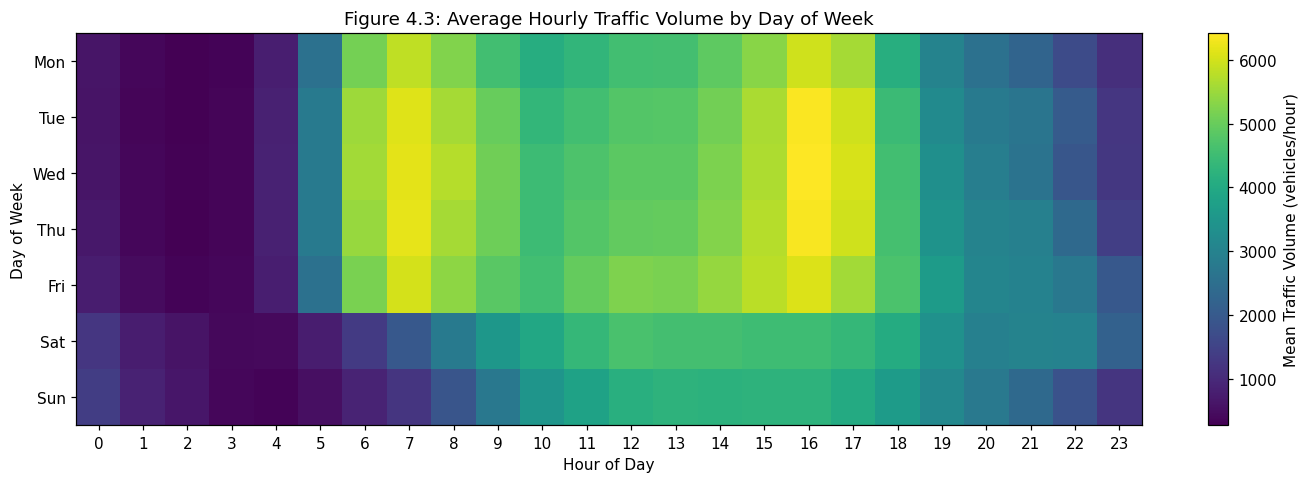

Table 4.3: Average Traffic by Weekday and Hour


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,,,,
0,633.15,387.36,294.29,341.21,802.23,2575.52,5138.95,5826.68,5249.41,4562.91,4106.13,4318.05,4556.82,4581.71,4881.59,5326.24,5966.97,5587.91,4117.80,3022.00,2562.77,2262.84,1688.62,1101.25
1,595.68,368.85,276.71,351.14,840.63,2774.72,5508.26,6114.84,5591.52,4983.45,4342.58,4552.87,4772.74,4788.58,5100.20,5638.84,6389.14,5969.09,4456.34,3215.91,2811.41,2655.59,2043.88,1244.69
2,624.23,392.37,303.39,370.87,863.19,2808.58,5574.37,6171.80,5740.70,5076.52,4486.76,4695.28,4871.32,4879.15,5198.42,5665.18,6414.26,6054.51,4567.23,3331.59,2907.41,2622.27,1925.02,1266.01
3,660.87,395.34,297.51,364.96,846.88,2785.86,5476.48,6175.75,5594.26,5055.92,4493.00,4781.97,4951.22,4959.89,5275.78,5738.91,6344.26,5963.16,4598.45,3427.96,3027.18,2961.27,2363.06,1410.44
4,760.25,455.29,342.84,385.56,797.49,2562.44,5180.92,6029.38,5363.11,4834.02,4567.57,4959.57,5215.84,5183.72,5445.36,5777.55,6079.12,5557.65,4678.65,3656.24,3068.02,3009.14,2724.26,1975.85
5,1259.11,776.10,598.70,411.03,422.63,759.82,1318.28,1958.35,2813.49,3533.40,3968.63,4359.23,4650.52,4582.93,4568.25,4512.23,4504.73,4353.87,4048.05,3380.04,2950.21,3013.73,3005.89,2193.70
6,1389.04,860.52,642.01,387.65,341.03,525.72,896.80,1233.06,1901.81,2730.72,3471.21,3808.23,4152.70,4233.00,4218.87,4235.48,4248.33,4023.15,3653.31,3136.22,2753.77,2380.67,1819.11,1223.99


In [50]:
# STEP 1: Create weekday and hour columns

observed["weekday"] = observed.index.dayofweek

observed["hour"] = observed.index.hour


# STEP 2: Calculate average traffic for each weekday and hour

heatmap_data = observed.pivot_table(
    index="weekday",
    columns="hour",
    values="traffic_volume",
    aggfunc="mean"
)


# STEP 3: Define weekday names

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


# STEP 4: Create the heatmap

fig, ax = plt.subplots(figsize=(13, 4.5))

image = ax.imshow(
    heatmap_data,
    cmap="viridis",
    aspect="auto"
)


# STEP 5: Add axis labels

ax.set_title(
    "Figure 4.3: Average Hourly Traffic Volume by Day of Week"
)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Day of Week")


# STEP 6: Set X-axis values

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))


# STEP 7: Set Y-axis values

ax.set_yticks(range(7))
ax.set_yticklabels(days)


# STEP 8: Add a color bar

plt.colorbar(
    image,
    ax=ax,
    label="Mean Traffic Volume (vehicles/hour)"
)


# STEP 9: Save and display

plt.tight_layout()

plt.savefig(
    OUT / "03_hour_week_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# STEP 10: Display the calculated values

print("Table 4.3: Average Traffic by Weekday and Hour")

display(heatmap_data.round(2))

#### 4.3.3 Observations

**Figure 4.3: Average Hourly Traffic Volume by Day of Week**

1. **Weekday traffic exhibits two distinct peaks.** From Monday to Friday, traffic volume increases sharply during the morning hours (06:00–08:00) and reaches another peak during the afternoon (15:00–17:00).

2. **The highest average traffic volume occurs on Wednesday at 16:00**, reaching approximately **6,414.26 vehicles per hour**. Tuesday at 16:00 also records a high average traffic volume of approximately 6,389.14 vehicles per hour.

3. **Morning traffic is consistently high on weekdays.** Between Tuesday and Thursday, average traffic volume at 07:00 exceeds 6,100 vehicles per hour. This indicates a recurring morning peak during the working week.

4. **Weekend mornings exhibit substantially lower traffic volumes.** At 07:00, Saturday records approximately 1,958.35 vehicles per hour, while Sunday records approximately 1,233.06 vehicles per hour. In comparison, Wednesday records approximately 6,171.80 vehicles per hour at the same time.

5. **Weekend traffic increases gradually throughout the morning.** Unlike weekdays, Saturday and Sunday do not show a sharp early-morning increase. Instead, traffic volume rises progressively and reaches relatively high levels during the afternoon.

6. **Early-morning traffic remains low throughout the week.** Traffic volumes between approximately 01:00 and 04:00 are generally lower than daytime traffic volumes. The lowest value in Table 4.3 occurs on Tuesday at 02:00, with approximately **276.71 vehicles per hour**.

7. **Friday evening traffic remains comparatively elevated.** At 22:00, Friday records approximately 2,724.26 vehicles per hour, compared with 1,688.62 vehicles per hour on Monday. This suggests a difference in late-evening traffic patterns toward the end of the working week.

#### 4.3.4 Inferences

**1. Traffic patterns depend on both hour of day and day of week**

The heatmap demonstrates that traffic volume at a particular hour varies substantially depending on the weekday.

For example, Wednesday at 07:00 records approximately 6,171.80 vehicles per hour, while Sunday at the same hour records approximately 1,233.06 vehicles per hour.

This indicates that hour of day alone does not fully describe traffic behavior.

**Forecasting implication:** Including both hour-of-day and day-of-week information may help the model distinguish different traffic-demand patterns.

**2. Weekday traffic patterns are consistent with commuting activity**

The repeated morning and afternoon peaks from Monday to Friday are consistent with typical commuting patterns.

The sharp morning increase and high afternoon demand suggest that travel activity may be associated with regular working schedules.

However, the dataset does not directly identify individual journey purposes, so this interpretation remains a plausible explanation rather than a confirmed cause.

**3. Weekend traffic follows a different daily pattern**

Saturday and Sunday exhibit lower morning traffic and a more gradual increase toward midday and afternoon.

This suggests that weekend travel behavior differs from weekday travel behavior.

**Forecasting implication:** A weekend indicator may help distinguish weekday and weekend traffic patterns.

**4. Historical traffic at corresponding weekly hours may be informative**

The similarity of traffic patterns across weekdays suggests that observations from the same hour in previous weeks may contain useful predictive information.

For example, traffic at 07:00 on one Wednesday may provide information relevant to forecasting traffic at 07:00 on the following Wednesday.

**Forecasting implication:** The `lag_168` feature, representing traffic volume from the same hour one week earlier, is a reasonable candidate for model development.

Its actual predictive usefulness must be evaluated experimentally.

#### 4.3.5 Conclusions

The hour-of-week heatmap reveals clear differences in traffic-volume patterns across weekdays and weekends.

Weekdays exhibit pronounced morning and afternoon peaks, while weekends show lower early-morning traffic and a more gradual increase toward afternoon hours.

The highest average traffic volume occurs on Wednesday at 16:00, with approximately 6,414.26 vehicles per hour. In contrast, the lowest average traffic volume occurs on Tuesday at 02:00, with approximately 276.71 vehicles per hour.

These findings indicate that traffic volume varies with both the hour of day and the day of week.

The analysis supports investigating temporal predictors such as hour of day, day of week, weekend indicators, and historical traffic lags in the forecasting model.

Overall, Figure 4.3 provides evidence of recurring daily and weekly traffic patterns, which are relevant to the development of time-series forecasting models.


### 4.4 Holiday vs Non-Holiday Traffic Analysis

To compare the mean and median traffic volumes recorded during holidays and non-holidays.

In [51]:
# STEP 1: Identify holidays

observed["is_holiday"] = observed["holiday"] != "None"


# STEP 2: Calculate traffic statistics

holiday_summary = observed.groupby("is_holiday")["traffic_volume"].agg(
    ["mean", "median", "count"]
)


# STEP 3: Rename the index values

holiday_summary.index = holiday_summary.index.map({
    False: "Non-Holiday",
    True: "Holiday"
})


# STEP 4: Display results

print("Table 4.4: Holiday vs Non-Holiday Traffic Statistics")

display(holiday_summary.round(2))

Table 4.4: Holiday vs Non-Holiday Traffic Statistics


,mean,median,count
is_holiday,,,
Non-Holiday,3293.82,3433.0,40522
Holiday,863.96,812.0,53


#### 4.4.2 Observations

Table 4.4: Holiday vs Non-Holiday Traffic Statistics

Non-holiday periods record substantially higher average traffic volume. The mean traffic volume during non-holidays is approximately 3,293.82 vehicles per hour, compared with 863.96 vehicles per hour during holidays.

Holiday traffic is approximately 73.8% lower than non-holiday traffic. The difference between the two mean traffic volumes is approximately 2,429.86 vehicles per hour.

Median traffic volume also differs considerably. Non-holiday observations have a median traffic volume of 3,433 vehicles per hour, whereas holiday observations have a median of 812 vehicles per hour.

The dataset contains a large imbalance in sample sizes. There are 40,522 non-holiday observations but only 53 holiday observations. Holiday records represent approximately 0.13% of the 40,575 observed hourly records.

Both mean and median traffic volumes are lower for holiday observations. This suggests that the difference is not limited to the mean alone.

#### 4.4.3 Inferences

**1. Holiday periods are associated with lower observed traffic volume**

The substantial difference in mean and median traffic volumes suggests that the recorded holiday observations are associated with reduced traffic demand.

This pattern is consistent with changes in commuting and travel activity during public holidays.

However, the analysis establishes an association rather than a causal relationship.

**2. Holiday information may be useful for forecasting**

The observed differences suggest that holiday information could help a forecasting model distinguish regular traffic patterns from unusual demand conditions.

Forecasting implication: A holiday indicator may be considered as an additional calendar-based predictor, provided the holiday information is known at the time of prediction.

# 5. Feature Engineering

**The objective of feature engineering is to create input variables that help predict traffic volume for the next hour.**

In [52]:
# STEP 1: Create a new DataFrame

df_model = hourly[["traffic_volume"]].copy()


# STEP 2: Create calendar features

df_model["hour"] = df_model.index.hour

df_model["day_of_week"] = df_model.index.dayofweek

df_model["month"] = df_model.index.month

df_model["is_weekend"] = (df_model["day_of_week"] >= 5).astype(int)


# STEP 3: Create historical traffic features

df_model["lag_1"] = df_model["traffic_volume"].shift(1)

df_model["lag_24"] = df_model["traffic_volume"].shift(24)

df_model["lag_168"] = df_model["traffic_volume"].shift(168)


# STEP 4: Create rolling average feature

df_model["rolling_mean_24"] = (
    df_model["traffic_volume"].shift(1).rolling(24).mean()
)


# STEP 5: Remove rows with missing values

print("Rows before removing missing values:", len(df_model))

df_model = df_model.dropna()

print("Rows after removing missing values:", len(df_model))


# STEP 6: Separate input features and target

X = df_model.drop(columns=["traffic_volume"])

y = df_model["traffic_volume"]


# STEP 7: Display results

print("Number of features:", X.shape[1])

print("Feature names:", X.columns.tolist())

display(df_model.head())

Rows before removing missing values: 52551
Rows after removing missing values: 28040
Number of features: 8
Feature names: ['hour', 'day_of_week', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24']


,traffic_volume,hour,day_of_week,month,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24
date_time,,,,,,,,,
2012-10-12 14:00:00,5758.0,14,4,10,0,5383.0,5557.0,6108.0,3782.375000
2012-10-12 15:00:00,5889.0,15,4,10,0,5758.0,5818.0,6128.0,3790.750000
2012-10-12 16:00:00,6057.0,16,4,10,0,5889.0,6272.0,6069.0,3793.708333
2012-10-12 17:00:00,6028.0,17,4,10,0,6057.0,5944.0,6169.0,3784.750000
2012-10-12 18:00:00,5257.0,18,4,10,0,6028.0,4949.0,5384.0,3788.250000


# 6. Model Development and Evaluation

**Why use Ridge Regression?**

Ridge Regression is a linear regression model with regularization.

It learns the relationship between the input features and traffic volume while penalizing excessively large model coefficients.

Ridge Regression is suitable as an initial model because it is relatively simple, computationally efficient, and easy to interpret.

However, it may not capture complex nonlinear traffic patterns as effectively as more advanced models.

#### 6.1 Train-Test Split

In [53]:
# STEP 1: Calculate split positions

n = len(X)

train_end = int(n * 0.70)
val_end = int(n * 0.85)


# STEP 2: Split input features

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]


# STEP 3: Split target values

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]


# STEP 4: Display split information

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining period:", X_train.index.min(), "to", X_train.index.max())
print("Validation period:", X_val.index.min(), "to", X_val.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training samples: 19628
Validation samples: 4206
Testing samples: 4206

Training period: 2012-10-12 14:00:00 to 2017-09-24 09:00:00
Validation period: 2017-09-24 10:00:00 to 2018-04-04 04:00:00
Testing period: 2018-04-04 05:00:00 to 2018-09-30 23:00:00


#### 6.2 Baseline Prediction

***The predicted traffic volume for the next hour equals the traffic volume recorded during the previous hour.***

In [54]:
# Previous-hour traffic is our baseline prediction

baseline_pred = X_val["lag_1"]

print("First five baseline predictions:")

display(baseline_pred.head())

First five baseline predictions:


,lag_1
date_time,
2017-09-24 10:00:00,3460.0
2017-09-24 11:00:00,4689.0
2017-09-24 12:00:00,4745.0
2017-09-24 13:00:00,4386.0
2017-09-24 14:00:00,4329.0


#### 6.3 Train Ridge Regression

In [55]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


# STEP 1: Create model

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=100)
)


# STEP 2: Train model

model.fit(X_train, y_train)


# STEP 3: Predict validation traffic

ridge_pred = model.predict(X_val)


# STEP 4: Display predictions

print("First five Ridge predictions:")

print(ridge_pred[:5])

First five Ridge predictions:
[3717.04072794 4547.63903294 4631.14013225 4270.54925243 4210.86871018]


#### 6.3 Model Evalaution

**1. Mean Absolute Error (MAE)**

MAE measures the average absolute difference between actual and predicted traffic volumes.

For example, if MAE is 300 vehicles/hour, predictions differ from actual values by approximately 300 vehicles/hour on average.

***Lower MAE is better.***

**2. Root Mean Squared Error (RMSE)**

RMSE gives greater weight to large prediction errors.

It is useful when large forecasting mistakes are particularly undesirable.

***Lower RMSE is better.***

**3. R² Score**

R² measures how well the model explains variation in traffic volume relative to predicting the evaluation set's mean.
- 1.0 indicates perfect predictions.
- 0.0 indicates performance equivalent to predicting the evaluation set mean.
- Negative values indicate worse performance than that reference.

***Higher R² is better.***

In [56]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# Function to calculate evaluation metrics

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    r2 = r2_score(actual, predicted)

    return [mae, rmse, r2]


# Evaluate baseline

baseline_scores = evaluate_model(y_val, baseline_pred)


# Evaluate Ridge Regression

ridge_scores = evaluate_model(y_val, ridge_pred)


# Create comparison table

results = pd.DataFrame(
    [baseline_scores, ridge_scores],
    columns=["MAE", "RMSE", "R2"],
    index=["Naive Baseline", "Ridge Regression"]
)


print("Table 6.1: Validation Performance Comparison")

display(results.round(3))

Table 6.1: Validation Performance Comparison


,MAE,RMSE,R2
Naive Baseline,592.286,820.215,0.827
Ridge Regression,344.655,514.056,0.932


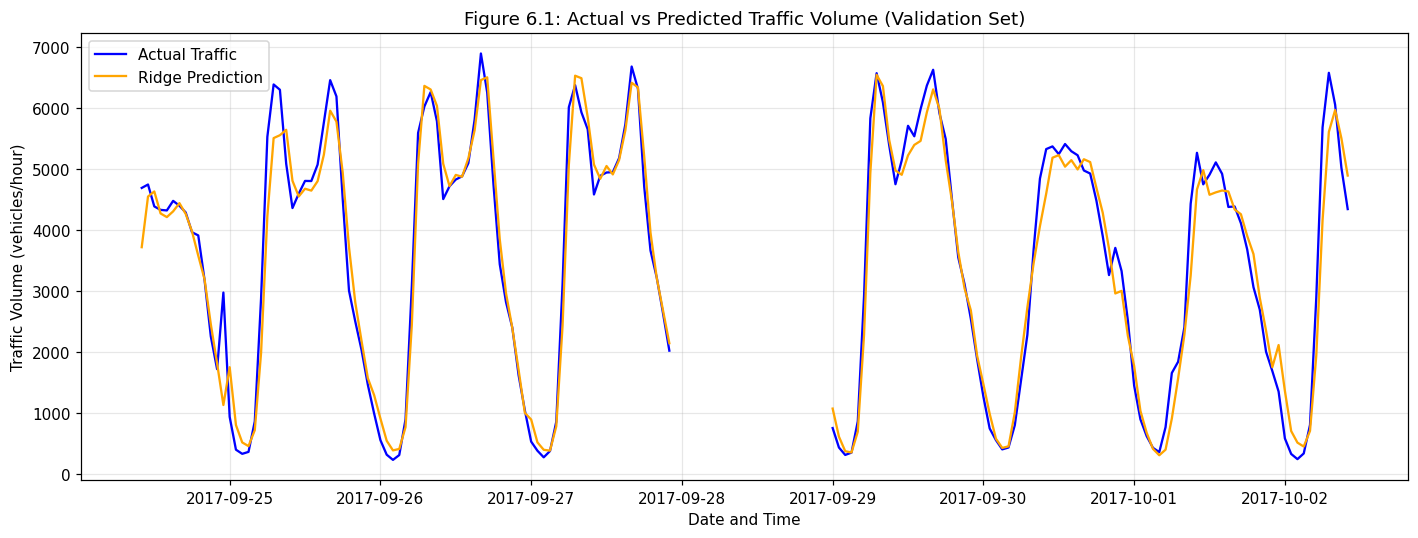

In [57]:
# STEP 1: Create prediction DataFrame

comparison = pd.DataFrame({
    "Actual": y_val,
    "Predicted": ridge_pred
})


# STEP 2: Select first 168 observations

sample = comparison.head(168).asfreq("h")


# STEP 3: Create graph

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    sample.index,
    sample["Actual"],
    label="Actual Traffic",
    color="blue"
)

ax.plot(
    sample.index,
    sample["Predicted"],
    label="Ridge Prediction",
    color="orange"
)


# STEP 4: Add title and labels

ax.set_title(
    "Figure 6.1: Actual vs Predicted Traffic Volume (Validation Set)"
)

ax.set_xlabel("Date and Time")
ax.set_ylabel("Traffic Volume (vehicles/hour)")

ax.legend()
ax.grid(alpha=0.3)


# STEP 5: Save and display

plt.tight_layout()

plt.savefig(
    OUT / "05_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6.4 Observations

1. ***The Ridge Regression predictions closely follow the overall pattern of actual traffic volume***. The predicted values generally increase and decrease alongside the observed traffic values, indicating that the model captures important temporal variations.

2. The model successfully represents recurring daily traffic patterns. Figure 6.1 shows repeated increases in traffic during high-demand periods and decreases during low-demand periods. The predicted curve follows most of these fluctuations.

3. The model captures several major traffic peaks. However, at certain peak periods, predicted traffic volume is slightly lower than the actual traffic volume, indicating some underestimation of high-demand conditions.

4. Low-traffic periods are generally predicted reasonably well. The predicted values follow the observed reductions in traffic during nighttime and other low-demand hours, although small differences remain.

5. Some prediction errors occur during sudden traffic changes. The model does not perfectly reproduce every abrupt increase or decrease in observed traffic volume.

6. A visible gap appears in the plotted time series around September 28–29, 2017. The plotted lines connect observations across this interval. Because the graph displays the first 168 eligible validation samples, these samples may not represent consecutive calendar hours.





#### 6.5 Conculsions

The validation results demonstrate that Ridge Regression provides more accurate one-hour-ahead traffic forecasts than the previous-hour naive baseline.

Ridge Regression achieves an MAE of 344.655 vehicles per hour, RMSE of 514.056 vehicles per hour, and R² score of 0.932. Compared with the baseline, these results represent reductions of approximately 41.81% in MAE and 37.33% in RMSE.

The predicted traffic values also follow the main daily traffic patterns observed in the validation dataset, although some prediction errors remain during peak periods and sudden traffic changes.

Overall, Ridge Regression provides a promising initial forecasting model. Further comparison with a daily seasonal baseline and evaluation on the independent test dataset are necessary before drawing final conclusions about forecasting performance.

### 6.6 Limitations of Forecasting Model

1. ***Difficulty in predicting sudden traffic fluctuations***: Although Ridge Regression captures the overall traffic patterns, some prediction errors occur during sudden increases and decreases in traffic volume, particularly around peak hours.

2. ***Limited ability to capture nonlinear relationships***:
 Ridge Regression is a linear model and may not fully capture complex relationships between traffic volume, time of day, and other influencing factors.

3. ***Missing historical observations***: The dataset contains missing traffic records, particularly during 2014–2015. Since the model uses historical lag features, observations with incomplete feature histories are excluded, reducing the available training data.

4. ***Limited input features***: The current model uses only historical traffic observations and calendar-based features. Other potentially relevant factors, such as weather conditions, road incidents, and special events, are not included.

5. ***Limited evaluation***: The current results are based on the validation dataset. Although Ridge Regression outperforms the previous-hour naive baseline, its performance against a daily seasonal baseline (lag_24) and on the independent test dataset has not yet been established.